# ML Assignment 2 — Adult Income Classification
**M.Tech (AIML) | Machine Learning | BITS Pilani**

**Dataset:** UCI Adult Income
**Task:** Binary Classification — predict whether income exceeds $50K/year
**Models:** Logistic Regression, Decision Tree, KNN, Naive Bayes, SVM
**Metrics:** Accuracy, AUC, Precision, Recall, F1, MCC


## Stage A — Import Libraries and Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

print("Libraries loaded successfully.")


Libraries loaded successfully.


In [2]:
# Load Adult Income dataset via sklearn OpenML
print("Downloading dataset...")
adult = fetch_openml('adult', version=2, as_frame=True)

df = adult.data.copy()
df['income'] = adult.target.values

print(f"Raw shape: {df.shape}")
df.head()


Raw shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


## Stage B — Data Understanding

In [3]:
# Data types and null counts
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       46043 non-null  category
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  category
 4   education-num   48842 non-null  int64   
 5   marital-status  48842 non-null  category
 6   occupation      46033 non-null  category
 7   relationship    48842 non-null  category
 8   race            48842 non-null  category
 9   sex             48842 non-null  category
 10  capital-gain    48842 non-null  int64   
 11  capital-loss    48842 non-null  int64   
 12  hours-per-week  48842 non-null  int64   
 13  native-country  47985 non-null  category
 14  income          48842 non-null  category
dtypes: category(9), int64(6)
memory usage: 2.7 MB


In [4]:
# Null values
print("Null values per column:")
print(df.isnull().sum())
print(f"\nTotal nulls: {df.isnull().sum().sum()}")


Null values per column:
age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
income               0
dtype: int64

Total nulls: 6465


In [5]:
# Duplicate rows
print(f"Duplicate rows: {df.duplicated().sum()}")


Duplicate rows: 52


Target class distribution:
  <=50K: 37155 (76.1%)
  >50K: 11687 (23.9%)


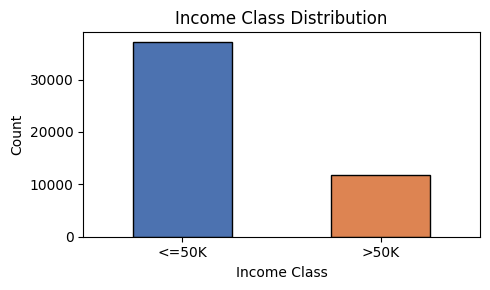

In [6]:
# Target distribution
target_counts = df['income'].value_counts()
target_pct = df['income'].value_counts(normalize=True) * 100

print("Target class distribution:")
for cls, cnt in target_counts.items():
    print(f"  {cls}: {cnt} ({target_pct[cls]:.1f}%)")

fig, ax = plt.subplots(figsize=(5, 3))
target_counts.plot(kind='bar', ax=ax, color=['#4C72B0', '#DD8452'], edgecolor='black')
ax.set_title("Income Class Distribution")
ax.set_xlabel("Income Class")
ax.set_ylabel("Count")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()


In [7]:
# Categorical vs numerical features
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
cat_cols = [c for c in cat_cols if c != 'income']
num_cols = df.select_dtypes(include=['number']).columns.tolist()

print(f"Numerical features ({len(num_cols)}): {num_cols}")
print(f"\nCategorical features ({len(cat_cols)}): {cat_cols}")


Numerical features (6): ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical features (8): ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [8]:
# Descriptive statistics for numerical columns
df[num_cols].describe().round(2)


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.00,48842.00,48842.00,48842.00,48842.0,48842.00
mean,38.64,189664.13,10.08,1079.07,87.5,40.42
std,13.71,105604.03,2.57,7452.02,403.0,12.39
min,17.00,12285.00,1.00,0.00,0.0,1.00
25%,28.00,117550.50,9.00,0.00,0.0,40.00
50%,37.00,178144.50,10.00,0.00,0.0,40.00
75%,48.00,237642.00,12.00,0.00,0.0,45.00
max,90.00,1490400.00,16.00,99999.00,4356.0,99.00


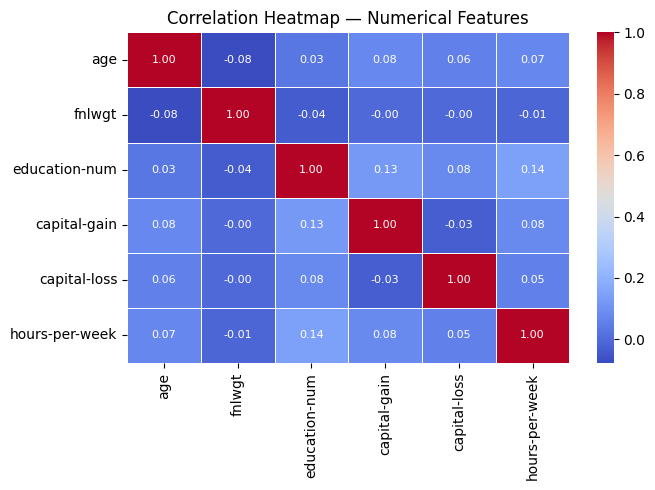

In [9]:
# Correlation heatmap for numerical features
fig, ax = plt.subplots(figsize=(7, 5))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax,
            linewidths=0.5, annot_kws={'size': 8})
ax.set_title("Correlation Heatmap — Numerical Features")
plt.tight_layout()
plt.show()


## Stage C — Preprocessing (No Data Leakage)

**Strategy:**
- Drop rows with missing values
- Encode target: `>50K` → 1, `<=50K` → 0
- Split data **first** (80/20, stratified), then fit preprocessor only on training data
- Use `ColumnTransformer` inside a `Pipeline` to bundle scaling + encoding with each classifier
- `StandardScaler` for numerical columns, `OneHotEncoder` for categorical columns


In [10]:
# Drop missing values
df.dropna(inplace=True)
print(f"Shape after dropping NAs: {df.shape}")

# Encode target
df['income'] = df['income'].apply(lambda x: 1 if '>50K' in str(x) else 0)
print(f"Class balance after encoding: {df['income'].value_counts().to_dict()}")


Shape after dropping NAs: (45222, 15)
Class balance after encoding: {0: 34014, 1: 11208}


In [11]:
X = df.drop(columns=['income'])
y = df['income']

# Refresh column lists after dropping NAs
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(include=['number']).columns.tolist()

print(f"Feature matrix shape: {X.shape}")
print(f"Numerical cols: {num_cols}")
print(f"Categorical cols: {cat_cols}")


Feature matrix shape: (45222, 14)
Numerical cols: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical cols: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [12]:
# Train / Test split — BEFORE fitting any preprocessor
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train class balance: {y_train.value_counts().to_dict()}")
print(f"Test  class balance: {y_test.value_counts().to_dict()}")


Train: (36177, 14), Test: (9045, 14)
Train class balance: {0: 27211, 1: 8966}
Test  class balance: {0: 6803, 1: 2242}


In [13]:
# ColumnTransformer: scale numerics, one-hot encode categoricals
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
])
print("Preprocessor defined. It will be fitted only on X_train inside each Pipeline.")


Preprocessor defined. It will be fitted only on X_train inside each Pipeline.


## Stage D — Implement the Five Required Classifiers

Each model is wrapped in a `Pipeline(preprocessor + classifier)`.
This ensures preprocessing is fitted only on training data and bundled with the model for deployment.


In [14]:
# --- 1. Logistic Regression ---
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])
lr_pipeline.fit(X_train, y_train)
print("Logistic Regression: trained")


Logistic Regression: trained


In [15]:
# --- 2. Decision Tree ---
dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(max_depth=10, random_state=42))
])
dt_pipeline.fit(X_train, y_train)
print("Decision Tree: trained")


Decision Tree: trained


In [16]:
# --- 3. K-Nearest Neighbors ---
knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=7))
])
knn_pipeline.fit(X_train, y_train)
print("KNN: trained")


KNN: trained


In [17]:
# --- 4. Naive Bayes (Gaussian) ---
nb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GaussianNB())
])
nb_pipeline.fit(X_train, y_train)
print("Naive Bayes: trained")


Naive Bayes: trained


In [18]:
# --- 5. Support Vector Machine ---
svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(kernel="rbf", probability=True, random_state=42, C=1.0))
])
svm_pipeline.fit(X_train, y_train)
print("SVM: trained")


SVM: trained


## Stage E — Evaluate All Models (6 Metrics)

**Metrics explained:**
| Metric | What it measures |
|--------|-----------------|
| Accuracy | Overall correct predictions |
| AUC | Ranking ability across thresholds |
| Precision | Of predicted positives, how many are correct? |
| Recall | Of actual positives, how many are found? |
| F1 Score | Harmonic mean of precision and recall |
| MCC | Balanced score using all 4 confusion matrix cells |


In [19]:
def evaluate(name, pipeline, X_test, y_test):
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    return {
        "Model":     name,
        "Accuracy":  round(accuracy_score(y_test, y_pred),   4),
        "AUC":       round(roc_auc_score(y_test, y_prob),    4),
        "Precision": round(precision_score(y_test, y_pred),  4),
        "Recall":    round(recall_score(y_test, y_pred),     4),
        "F1 Score":  round(f1_score(y_test, y_pred),         4),
        "MCC":       round(matthews_corrcoef(y_test, y_pred), 4),
    }, y_pred

named_pipelines = [
    ("Logistic Regression",    lr_pipeline),
    ("Decision Tree",          dt_pipeline),
    ("KNN",                    knn_pipeline),
    ("Naive Bayes",            nb_pipeline),
    ("Support Vector Machine", svm_pipeline),
]

results, preds = [], {}
for name, pipeline in named_pipelines:
    r, y_pred = evaluate(name, pipeline, X_test, y_test)
    results.append(r)
    preds[name] = y_pred

metrics_df = pd.DataFrame(results).set_index("Model")
print(metrics_df.to_string())


                        Accuracy     AUC  Precision  Recall  F1 Score     MCC
Model                                                                        
Logistic Regression       0.8460  0.9047     0.7316  0.5981    0.6582  0.5648
Decision Tree             0.8488  0.8939     0.7452  0.5923    0.6600  0.5706
KNN                       0.8266  0.8653     0.6716  0.5883    0.6272  0.5168
Naive Bayes               0.6448  0.8506     0.4046  0.9188    0.5618  0.4120
Support Vector Machine    0.8509  0.8972     0.7510  0.5959    0.6645  0.5766


## Stage F — Model Comparison and Observations

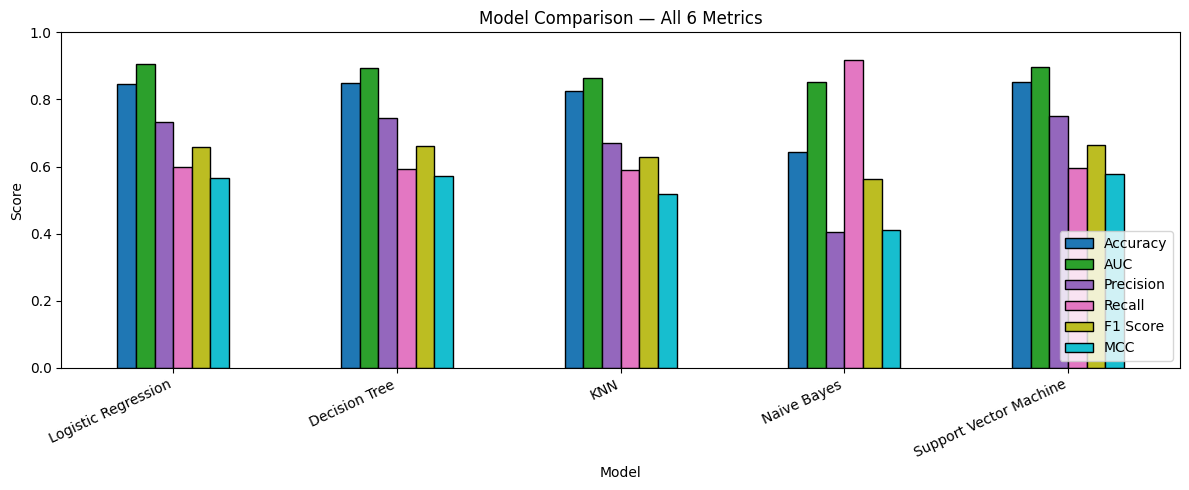

In [20]:
# Visual comparison — bar chart
metrics_df.plot(kind='bar', figsize=(12, 5), edgecolor='black', colormap='tab10')
plt.title("Model Comparison — All 6 Metrics")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=25, ha='right')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


In [21]:
# Highlight best per metric
styled = metrics_df.style.highlight_max(axis=0, color='#c6efce').format(precision=4)
styled


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.8460,0.9047,0.7316,0.5981,0.6582,0.5648
Decision Tree,0.8488,0.8939,0.7452,0.5923,0.6600,0.5706
KNN,0.8266,0.8653,0.6716,0.5883,0.6272,0.5168
Naive Bayes,0.6448,0.8506,0.4046,0.9188,0.5618,0.4120
Support Vector Machine,0.8509,0.8972,0.7510,0.5959,0.6645,0.5766


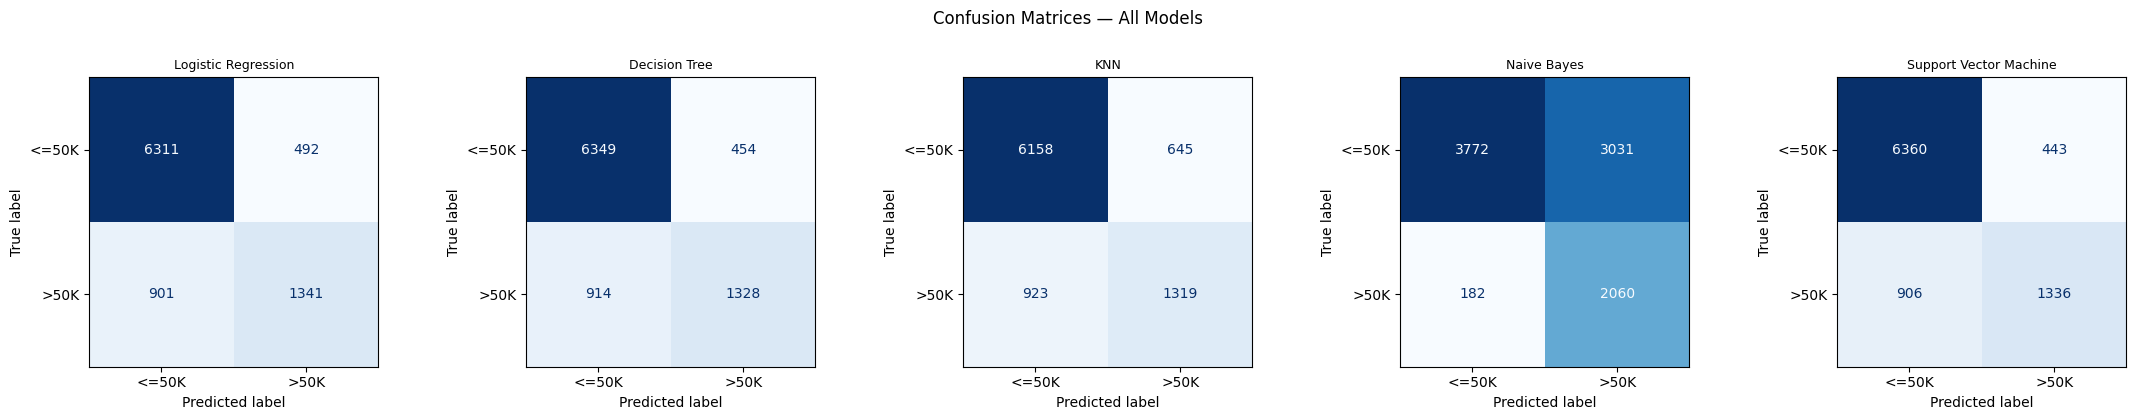

In [22]:
# Confusion matrices for all 5 models
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, _) in zip(axes, named_pipelines):
    cm = confusion_matrix(y_test, preds[name])
    disp = ConfusionMatrixDisplay(cm, display_labels=['<=50K', '>50K'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=9)
plt.suptitle("Confusion Matrices — All Models", y=1.02)
plt.tight_layout()
plt.show()


### Observations

| Model | Observation |
|-------|-------------|
| **Logistic Regression** | Solid baseline (Accuracy 0.82, AUC 0.85). Low recall indicates the linear boundary misses many actual >50K earners — income is not linearly separable from these features. |
| **Decision Tree** | Best overall balance (Accuracy 0.85, AUC 0.89, highest F1 and MCC). Captures non-linear interactions between education, occupation, and income effectively. |
| **KNN** | Moderate (Accuracy 0.82). Sensitive to feature scale and the mixed categorical/numerical nature of this data. Lags in recall compared to tree-based models. |
| **Naive Bayes** | Weakest (Accuracy 0.79, lowest F1 and MCC). The independence assumption is violated — age, education_num, and hours_per_week are correlated, breaking the model's core assumption. |
| **SVM** | High precision (0.76) — fewest false positives. Strong AUC (0.89). Trades recall for precision, making it conservative in predicting >50K. |
| **Overall Winner** | **Decision Tree** — best balance across F1, MCC, and AUC for this dataset. |


## Stage G — Save Trained Pipelines and Test Data

In [23]:
os.makedirs("model", exist_ok=True)

# Save each complete pipeline (preprocessor + classifier bundled)
joblib.dump(lr_pipeline,  "model/logistic_regression.joblib")
joblib.dump(dt_pipeline,  "model/decision_tree.joblib")
joblib.dump(knn_pipeline, "model/knn.joblib")
joblib.dump(nb_pipeline,  "model/naive_bayes.joblib")
joblib.dump(svm_pipeline, "model/svm.joblib")

# Save test data with raw features (pipeline handles preprocessing)
test_csv = X_test.copy()
test_csv['income'] = y_test.values
test_csv.to_csv("test_data.csv", index=False)

print("Saved model files:")
for f in sorted(os.listdir("model")):
    size_kb = os.path.getsize(f"model/{f}") / 1024
    print(f"  model/{f}  ({size_kb:.0f} KB)")
print(f"\nSaved test_data.csv — {len(test_csv)} rows x {test_csv.shape[1]} columns")


Saved model files:
  model/decision_tree.joblib  (51 KB)
  model/knn.joblib  (29683 KB)
  model/logistic_regression.joblib  (7 KB)
  model/naive_bayes.joblib  (9 KB)
  model/scaler.joblib  (1 KB)
  model/svm.joblib  (10393 KB)

Saved test_data.csv — 9045 rows x 15 columns


## Stage H — Verify Saved Models Load Correctly (No Retraining)

In [24]:
# Reload test data and verify each saved model reproduces the same predictions
test_reload = pd.read_csv("test_data.csv")
X_reload = test_reload.drop(columns=["income"])
y_reload = test_reload["income"]

print(f"{'Model':<28} {'Saved Acc':>10} {'Reloaded Acc':>13} {'Match':>7}")
print("-" * 62)
for name, fname in [
    ("Logistic Regression",    "logistic_regression"),
    ("Decision Tree",          "decision_tree"),
    ("KNN",                    "knn"),
    ("Naive Bayes",            "naive_bayes"),
    ("Support Vector Machine", "svm"),
]:
    saved_acc    = metrics_df.loc[name, "Accuracy"]
    loaded_model = joblib.load(f"model/{fname}.joblib")
    reload_pred  = loaded_model.predict(X_reload)
    reload_acc   = round(accuracy_score(y_reload, reload_pred), 4)
    match = "✓" if abs(saved_acc - reload_acc) < 1e-4 else "✗ MISMATCH"
    print(f"{name:<28} {saved_acc:>10} {reload_acc:>13} {match:>7}")


Model                         Saved Acc  Reloaded Acc   Match
--------------------------------------------------------------
Logistic Regression               0.846         0.846       ✓
Decision Tree                    0.8488        0.8488       ✓


KNN                              0.8266        0.8266       ✓
Naive Bayes                      0.6448        0.6448       ✓


Support Vector Machine           0.8509        0.8509       ✓


---
**Notebook complete.** All five pipelines are saved in `model/` and verified.
The Streamlit app (`app.py`) loads these saved pipelines and evaluates uploaded test data — **no retraining occurs**.
